In [1]:
import sys
print(sys.executable)

c:\Users\George\boston-bike-demand-forecasting\.venv\Scripts\python.exe


In [2]:
import os
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
import plotly.express as px
from data_profiling import ProfileReport

%matplotlib inline

# Consistent visualisation style
sns.set_theme(style="whitegrid", context="notebook")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

# Locate the project root
project_root = Path().resolve().parents[0]

# Set the working directory
os.chdir(project_root)

# Add the project root to the Python path
sys.path.append(str(project_root))

## Data Description

In [3]:

# Load the dataset
data = pd.read_parquet("data/02_intermediate/blue_bike_boston_clean.parquet")

In [4]:
data.head(5)

,datetime,hour,day,weekday,weekend,holiday,month,year,temp_c,humidity,wind_kmh,pressure_hpa,weather,casual_duration,member_duration,total_duration,casual_riders,member_riders,total_riders
0,2022-01-01 00:00:00,0,1,5,1,1,1,2022,6.70,89.00,7.60,1014.90,Cloudy,554672.00,96509.00,651181.00,28,97,125
1,2022-01-01 01:00:00,1,1,5,1,1,1,2022,6.70,89.00,7.60,1014.70,Cloudy,46276.00,58472.00,104748.00,31,61,92
2,2022-01-01 02:00:00,2,1,5,1,1,1,2022,6.70,89.00,7.60,1014.70,Cloudy,377839.00,45191.00,423030.00,32,41,73
3,2022-01-01 03:00:00,3,1,5,1,1,1,2022,6.70,96.00,5.40,1014.20,Cloudy,2537734.00,37167.00,2574901.00,54,41,95
4,2022-01-01 04:00:00,4,1,5,1,1,1,2022,7.20,93.00,5.40,1014.40,Cloudy,911448.00,43178.00,954626.00,49,42,91


In [5]:
# Display the shape of the dataset
print(f"Dataset shape: {data.shape}")

Dataset shape: (21079, 19)


In [6]:
# Display column names
print(data.columns.tolist())

['datetime', 'hour', 'day', 'weekday', 'weekend', 'holiday', 'month', 'year', 'temp_c', 'humidity', 'wind_kmh', 'pressure_hpa', 'weather', 'casual_duration', 'member_duration', 'total_duration', 'casual_riders', 'member_riders', 'total_riders']


In [7]:
# Display dataset information
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21079 entries, 0 to 21078
Data columns (total 19 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   datetime         21079 non-null  datetime64[us]
 1   hour             21079 non-null  int32         
 2   day              21079 non-null  int32         
 3   weekday          21079 non-null  int32         
 4   weekend          21079 non-null  int64         
 5   holiday          21079 non-null  int64         
 6   month            21079 non-null  int32         
 7   year             21079 non-null  int32         
 8   temp_c           21079 non-null  float64       
 9   humidity         21079 non-null  float64       
 10  wind_kmh         21079 non-null  float64       
 11  pressure_hpa     21079 non-null  float64       
 12  weather          21079 non-null  object        
 13  casual_duration  21079 non-null  float64       
 14  member_duration  21079 non-null  float

## Feature Description

The dataset contains hourly bike-sharing observations from Boston, covering January 2022 to May 2024. It includes temporal features, weather conditions, ride durations, and rider counts.

#### 1. Temporal Features

* **`datetime`** — Date and time of the observation, recorded at hourly intervals.

* **`hour`** — Hour of the day.

  * Range: `[0, 23]`
  * `0` = midnight

* **`day`** — Day of the month.

  * Range: `[1, 31]`

* **`weekday`** — Day of the week, represented numerically.

  * `0` = Monday
  * `1` = Tuesday
  * `2` = Wednesday
  * `3` = Thursday
  * `4` = Friday
  * `5` = Saturday
  * `6` = Sunday

* **`weekend`** — Indicates whether the observation falls on a weekend.

  * `0` = Weekday
  * `1` = Weekend

* **`holiday`** — Indicates whether the date is classified as a holiday.

  * `0` = Not a holiday
  * `1` = Holiday

* **`month`** — Month of the year.

  * Range: `[1, 12]`

* **`year`** — Calendar year of the observation.

  * Values in this dataset: `2022`, `2023`, `2024`

#### 2. Environmental Features

* **`temp_c`** — Air temperature measured in degrees Celsius (°C).

* **`humidity`** — Relative humidity, expressed as a percentage (%).

* **`wind_kmh`** — Wind speed measured in kilometres per hour (km/h).

* **`pressure_hpa`** — Atmospheric pressure measured in hectopascals (hPa).

* **`weather`** — Categorical description of the weather conditions during the observation.

    * `Clear`, `Fair`, `Cloudy`, `Rain`, `Snow` 

#### 3. Ride Duration Features

* **`casual_duration`** — Recorded ride duration associated with casual riders, expressed in seconds.

* **`member_duration`** — Recorded ride duration associated with member riders, expressed in seconds.

* **`total_duration`** — Recorded total ride duration, expressed in seconds.

#### 4. Rider Count Features

* **`casual_riders`** — Number of rides attributed to casual riders during the observation period.

* **`member_riders`** — Number of rides attributed to member riders during the observation period.

* **`total_riders`** — Total number of rides recorded during the observation period. This is the target variable for the demand forecasting project.

  Where the dataset defines total demand as the sum of casual and member rides:

  `total_riders = casual_riders + member_riders`

## Data Profiling

In [8]:
profile = ProfileReport(
    data,
    title="Boston Blue Bike — Data Profiling Report",
    explorative=True
)

profile

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 19/19 [00:00<00:00, 57.07it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

### Data Profiling Observations

1. **No Missing Values**
   All 19 variables contain 21,079 non-null observations, with no missing values detected.

2. **No Duplicate Records**
   The profiling report identified no duplicate rows, indicating that no exact duplicate records were detected.

3. **Strong Relationships Between Variables**
   Several variables exhibit strong correlations. In particular, `casual_riders`, `member_riders`, and `total_riders` require further investigation because the component rider counts may directly determine the total.

4. **Zero Values in Multiple Variables**
   Zero values appear in variables such as `hour`, `weekday`, `temp_c`, `wind_kmh`, `casual_duration`, and `casual_riders`. These values must be assessed individually because some may represent valid observations.

5. **Holiday Feature Imbalance**
   The `holiday` variable has an imbalanced distribution, which is expected because holidays occur less frequently than non-holidays.

6. **Datetime Uniqueness**
   The `datetime` variable contains unique timestamps. However, further checks are required to confirm that the hourly time series has no missing time intervals.

7. **Weather and Demand Relationships**
   Weather conditions may influence bike demand. Their relationships with `total_riders` should be examined during EDA to identify potentially useful forecasting features.

8. **Potential Target Leakage**
   Variables such as `casual_riders`, `member_riders`, and potentially the duration-related columns require careful assessment before modelling to prevent information from the target period leaking into the predictors.



## Target and Feature Dependency Analysis

### Target Variable Analysis

In [9]:

#  TIME-SERIES VISUALISATION

# Ensure observations are chronologically ordered
df = data.sort_values("datetime").reset_index(drop=True)

# Create an interactive time-series plot
fig = px.line(
    df,
    x="datetime",
    y="total_riders",
    title="Boston Blue Bike — Hourly Demand Over Time",
    labels={
        "datetime": "Date and Time",
        "total_riders": "Total Riders per Hour"
    },
    hover_data={
        "datetime": "|%d %b %Y, %H:%M",
        "total_riders": ":,.0f"
    },
    template="plotly_white"
)

# Add a time-range slider and selector buttons
fig.update_xaxes(
    rangeslider_visible=True,
    rangeselector=dict(
        buttons=[
            dict(count=1, label="1M", step="month", stepmode="backward"),
            dict(count=3, label="3M", step="month", stepmode="backward"),
            dict(count=6, label="6M", step="month", stepmode="backward"),
            dict(count=1, label="1Y", step="year", stepmode="backward"),
            dict(step="all", label="All")
        ]
    ),
    title_text="Date and Time"
)

# Improve layout
fig.update_layout(
    title_x=0.5,
    title_font_size=20,
    xaxis_title="Date and Time",
    yaxis_title="Total Riders per Hour",
    hovermode="x unified",
    height=650
)

# Display the interactive figure
fig.show()

### Time-Series Visualisation — Observations

1. **Temporal Variation:** Hourly bike demand exhibits substantial fluctuations throughout the observation period, with frequent peaks and troughs.

2. **Potential Seasonality:** Demand appears to increase during some warmer months and decline towards winter, suggesting a possible seasonal pattern that requires further investigation.

3. **High-Demand Peaks:** Several periods exhibit exceptionally high demand, with the largest peak occurring around August–September 2022.

4. **Recurring Fluctuations:** Repeated peaks and troughs suggest potential hourly and weekly demand patterns.

5. **Periods of Reduced Demand:** Noticeable reductions in demand occur towards the end of 2022, late 2023 and early 2024.

6. **Forecasting Implications:** The observed fluctuations suggest that temporal features, including hour, weekday, month and seasonal indicators, may be useful predictors of bike demand.

In [9]:

# TARGET VARIABLE DESCRIPTIVE STATISTICS

# Select the target variable
target = data["total_riders"]

# Calculate descriptive statistics
target_stats = pd.DataFrame({
    "Statistic": [
        "Number of observations",
        "Mean",
        "Median",
        "Standard deviation",
        "Minimum",
        "25th percentile",
        "75th percentile",
        "Maximum",
        "Skewness",
        "Kurtosis",
        "Zero-demand observations"
    ],
    "Value": [
        target.count(),
        target.mean(),
        target.median(),
        target.std(),
        target.min(),
        target.quantile(0.25),
        target.quantile(0.75),
        target.max(),
        target.skew(),
        target.kurt(),
        (target == 0).sum()
    ]
})

display(target_stats.round(3))

,Statistic,Value
0,Number of observations,21079.00
1,Mean,421.76
2,Median,307.00
3,Standard deviation,410.43
4,Minimum,1.00
5,25th percentile,83.00
6,75th percentile,633.00
7,Maximum,2744.00
8,Skewness,1.32
9,Kurtosis,1.79


### Target Variable Analysis — Observations

1. **High Demand Variability:** The mean hourly demand is 421.76 riders, with a standard deviation of 410.43, indicating substantial fluctuations in demand.

2. **Mean–Median Difference:** The mean (421.76) exceeds the median (307), suggesting that higher-demand observations pull the average upwards.

3. **Positive Skewness:** The target has a skewness of 1.32, indicating a right-skewed distribution with a tail towards higher demand.

4. **Wide Demand Range:** Hourly demand ranges from 1 to 2,744 riders, demonstrating considerable variation across observations.

5. **Interquartile Range:** The middle 50% of observations fall between 83 and 633 riders, indicating a wide spread in typical hourly demand.

6. **No Zero-Demand Observations:** All observations record at least one rider.

7. **Positive Kurtosis:** The excess kurtosis of 1.79 suggests heavier tails than a normal distribution, warranting further visual investigation.

**Conclusion:** Hourly bike demand exhibits substantial variability and positive skewness. Visualising the target distribution will help establish its shape and identify unusually high-demand observations before making decisions about outlier treatment or target transformations.


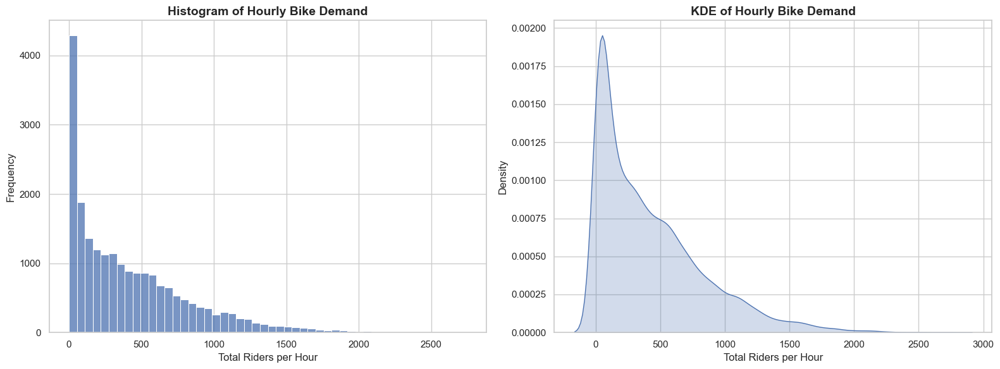

In [15]:
# Set visualisation theme
sns.set_theme(style="whitegrid", context="notebook")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Histogram of the target variable
sns.histplot(
    data=df,
    x="total_riders",
    bins=50,
    ax=axes[0]
)

axes[0].set_title(
    "Histogram of Hourly Bike Demand",
    fontsize=14,
    fontweight="bold"
)
axes[0].set_xlabel("Total Riders per Hour")
axes[0].set_ylabel("Frequency")

# 2. KDE plot of the target variable
sns.kdeplot(
    data=df,
    x="total_riders",
    fill=True,
    ax=axes[1]
)

axes[1].set_title(
    "KDE of Hourly Bike Demand",
    fontsize=14,
    fontweight="bold"
)
axes[1].set_xlabel("Total Riders per Hour")
axes[1].set_ylabel("Density")

plt.tight_layout()
plt.show()

### Target Distribution — Key Observations

1. **Positive Skewness:** The histogram and KDE plot reveal a positively skewed target distribution, with most observations concentrated at lower demand levels and a long tail towards higher rider counts.

2. **Concentration of Demand:** The histogram shows that lower-demand observations occur more frequently than high-demand observations.

3. **High-Demand Peaks:** A relatively small proportion of observations exhibit exceptionally high hourly demand, contributing to the long right tail.

4. **Non-Normal Distribution:** The target distribution is not symmetrical. However, normality is not a prerequisite for the selected tree-based regression models.

5. **Forecasting Implications:** High-demand peaks should be retained unless evidence establishes that they are erroneous. Model evaluation should account for performance during both typical and exceptionally busy periods.

**Conclusion:** The target distribution exhibits substantial variability and positive skewness. These characteristics highlight the importance of capturing nonlinear demand patterns and evaluating forecasting performance across different demand levels.


### Hourly Demand Pattern

In [10]:
# Calculate hourly demand statistics
hourly_demand = (
    df.groupby("hour")["total_riders"]
    .agg(
        mean_demand="mean",
        median_demand="median",
        std_demand="std",
        observations="count"
    )
    .reset_index()
)

# Interactive line chart
fig = px.line(
    hourly_demand,
    x="hour",
    y="mean_demand",
    markers=True,
    title="Boston Blue Bike — Average Demand by Hour of Day",
    labels={
        "hour": "Hour of Day",
        "mean_demand": "Average Riders per Hour"
    },
    template="plotly_white",
    hover_data={
        "median_demand": ":.1f",
        "std_demand": ":.1f",
        "observations": True
    }
)

fig.update_layout(
    title_x=0.5,
    height=550,
    xaxis=dict(
        tickmode="linear",
        dtick=1,
        range=[0, 23]
    )
)

fig.show()

# Identify the hours with the highest and lowest mean demand
highest_hour = hourly_demand.loc[
    hourly_demand["mean_demand"].idxmax()
]

lowest_hour = hourly_demand.loc[
    hourly_demand["mean_demand"].idxmin()
]

print(
    f"Highest average demand: {highest_hour['mean_demand']:.2f} riders "
    f"at {int(highest_hour['hour']):02d}:00"
)

print(
    f"Lowest average demand: {lowest_hour['mean_demand']:.2f} riders "
    f"at {int(lowest_hour['hour']):02d}:00"
)

Highest average demand: 921.32 riders at 17:00
Lowest average demand: 48.34 riders at 04:00


#### Average Demand by Hour of Day — Observations

1. **Lowest Demand:** Average bike demand reaches its lowest level at approximately 04:00, indicating minimal usage during the early-morning hours.

2. **Morning Demand Increase:** Demand rises sharply between 05:00 and 08:00, reaching approximately 530 riders per hour at 08:00.

3. **Sustained Midday Demand:** Demand remains relatively high between 11:00 and 14:00, suggesting continued bike usage throughout the middle of the day.

4. **Evening Demand Peak:** The highest average demand occurs at approximately 17:00, reaching around 920 riders per hour.

5. **Post-Peak Decline:** Demand decreases after 17:00 and continues falling into the late evening.

6. **Forecasting Implications:** The pronounced daily demand pattern suggests that `hour` may be an important predictor for XGBoost, LightGBM and CatBoost.

### Average Demand by Days of Week

In [11]:

# Map weekday numbers to day names.
# This mapping assumes Monday=0 and Sunday=6.
day_names = {
    0: "Monday",
    1: "Tuesday",
    2: "Wednesday",
    3: "Thursday",
    4: "Friday",
    5: "Saturday",
    6: "Sunday"
}

# Calculate average demand by weekday
weekday_demand = (
    df.groupby("weekday")["total_riders"]
    .agg(
        mean_demand="mean",
        median_demand="median",
        observations="count"
    )
    .reset_index()
)

weekday_demand["day_name"] = weekday_demand["weekday"].map(day_names)

# Display summary statistics
display(weekday_demand.round(2))

# Plot average demand by day of week
fig = px.bar(
    weekday_demand,
    x="day_name",
    y="mean_demand",
    title="Boston Blue Bike — Average Demand by Day of Week",
    labels={
        "day_name": "Day of Week",
        "mean_demand": "Average Riders per Hour"
    },
    hover_data={
        "median_demand": ":.1f",
        "observations": True
    },
    category_orders={
        "day_name": [
            "Monday", "Tuesday", "Wednesday",
            "Thursday", "Friday", "Saturday", "Sunday"
        ]
    },
    template="plotly_white"
)

fig.update_layout(
    title_x=0.5,
    height=500
)

fig.show()

,weekday,mean_demand,median_demand,observations,day_name
0,0,391.86,295.00,3012,Monday
1,1,433.79,328.00,3020,Tuesday
2,2,447.83,335.50,3022,Wednesday
3,3,447.16,335.00,3022,Thursday
4,4,442.21,351.00,3000,Friday
5,5,411.68,275.00,3005,Saturday
6,6,377.44,240.00,2998,Sunday


#### Average Demand by Day of Week — Observations

1. **Higher Weekday Demand:** Average hourly demand is generally higher from Tuesday to Friday, with Wednesday and Thursday recording the highest levels.

2. **Monday Demand:** Monday exhibits lower average demand than the other weekdays.

3. **Reduced Weekend Demand:** Average demand declines on Saturday and Sunday, with Sunday recording the lowest level.

4. **Midweek Peak:** Wednesday and Thursday show the strongest average demand, suggesting differences in bike usage across the working week.

5. **Forecasting Implications:** The observed weekly variation suggests that `weekday` may be a useful predictor of bike demand.

**Conclusion:** Average hourly bike demand varies across the week, with stronger demand during the middle of the working week and lower demand over the weekend. 

### Weekday vs Weekend Demand

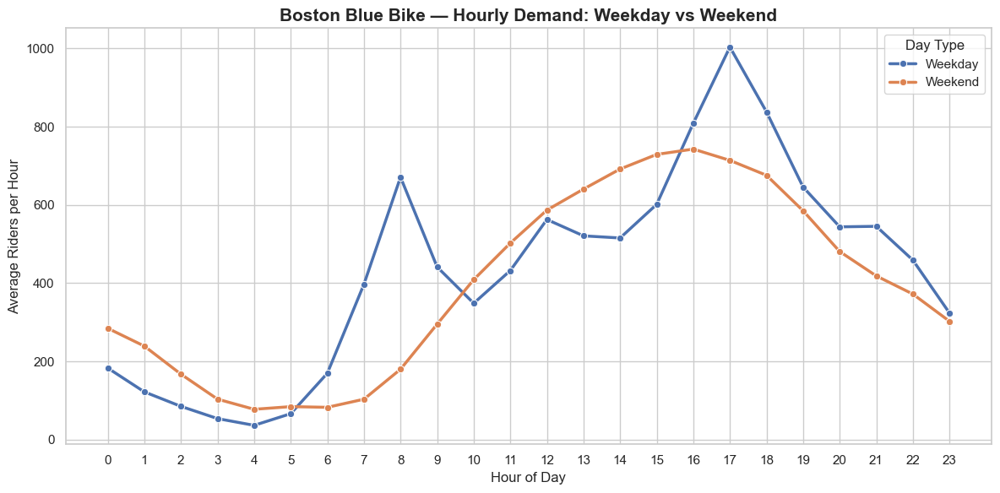

In [28]:
# Create readable day-type labels
df["day_type"] = df["weekend"].map({
    0: "Weekday",
    1: "Weekend"
})

# Calculate mean hourly demand by hour and day type
hourly_day_type = (
    df.groupby(["hour", "day_type"], as_index=False)["total_riders"]
    .mean()
)

sns.set_theme(style="whitegrid", context="notebook")

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=hourly_day_type,
    x="hour",
    y="total_riders",
    hue="day_type",
    marker="o",
    linewidth=2.5
)

plt.title(
    "Boston Blue Bike — Hourly Demand: Weekday vs Weekend",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Hour of Day")
plt.ylabel("Average Riders per Hour")
plt.xticks(range(24))
plt.legend(title="Day Type")
plt.tight_layout()
plt.show()

#### Hourly Demand by Day Type — Key Observations

1. **Distinct Weekday Commuting Peaks:** Weekday demand rises sharply in the morning, reaching approximately 670 riders per hour at 08:00, and peaks again at approximately 1,000 riders per hour at 17:00.

2. **Weekend Demand Peaks Later:** Weekend demand increases gradually through the morning and reaches its highest level at approximately 16:00, with around 740 riders per hour.

3. **Morning Demand Differences:** Weekday demand is substantially higher around 07:00–09:00, suggesting a strong morning commuting pattern that is less pronounced on weekends.

4. **Afternoon and Evening Differences:** Weekday demand exceeds weekend demand during much of the late afternoon and evening, particularly around 16:00–18:00.

5. **Overnight Demand:** Both day types experience relatively low demand during the early morning hours, especially between 02:00 and 05:00.

**Conclusion:** Weekday demand exhibits pronounced morning and evening peaks, whereas weekend demand follows a broader afternoon peak. These differences suggest that demand depends on both the hour of day and the type of day.


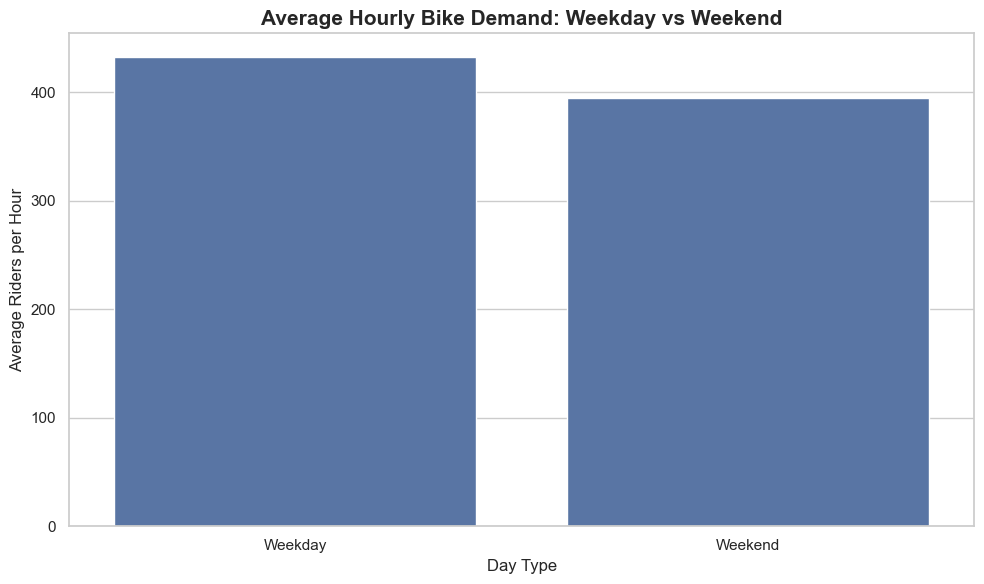

In [18]:
# Create readable labels
df["day_type"] = df["weekend"].map({
    0: "Weekday",
    1: "Weekend"
})

# Define category order
day_order = ["Weekday", "Weekend"]

# Create bar plot
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=df,
    x="day_type",
    y="total_riders",
    order=day_order,
    estimator="mean",
    errorbar=None
)

# Add chart titles and labels
ax.set_title(
    "Average Hourly Bike Demand: Weekday vs Weekend",
    fontsize=15,
    fontweight="bold"
)
ax.set_xlabel("Day Type", fontsize=12)
ax.set_ylabel("Average Riders per Hour", fontsize=12)

plt.tight_layout()
plt.show()

### Weekday vs Weekend Demand — Key Observations

1. **Higher Weekday Demand:** Average hourly demand is higher on weekdays (approximately 430 riders) than on weekends (approximately 395 riders).

2. **Demand Difference:** Weekday demand exceeds weekend demand by approximately 35 riders per hour, equivalent to roughly 9%.

3. **Potential Behavioural Pattern:** This difference may reflect variations in commuting and other travel activities between working days and weekends.

**Conclusion:** Average hourly bike demand is higher on weekdays than on weekends, indicating that the day type is a potentially useful temporal predictor for bike-demand forecasting.


###  Bike Demand by Month

In [19]:
# Calculate average hourly demand for each month
monthly_demand = (
    df.groupby("month")["total_riders"]
    .agg(
        average_demand="mean",
        median_demand="median",
        observations="count"
    )
    .reset_index()
)

# Display summary statistics
display(monthly_demand.round(2))

,month,average_demand,median_demand,observations
0,1,178.77,136.50,2174
1,2,243.30,179.50,2036
2,3,288.65,244.00,2228
3,4,429.11,383.00,2160
4,5,525.80,481.00,2209
5,6,525.26,491.50,1440
6,7,565.92,534.50,1488
7,8,624.27,579.00,1488
8,9,708.97,635.50,1440
9,10,573.14,540.00,1488


In [20]:
# Map month numbers to names
month_names = {
    1: "January",
    2: "February",
    3: "March",
    4: "April",
    5: "May",
    6: "June",
    7: "July",
    8: "August",
    9: "September",
    10: "October",
    11: "November",
    12: "December"
}

monthly_demand["month_name"] = monthly_demand["month"].map(month_names)

# Create interactive bar chart
fig = px.bar(
    monthly_demand,
    x="month_name",
    y="average_demand",
    title="Boston Blue Bike — Average Hourly Demand by Month",
    labels={
        "month_name": "Month",
        "average_demand": "Average Riders per Hour"
    },
    hover_data={
        "median_demand": ":.1f",
        "observations": True
    },
    category_orders={
        "month_name": list(month_names.values())
    },
    template="plotly_white",
    text_auto=".1f"
)

fig.update_layout(
    title_x=0.5,
    height=550,
    xaxis_title="Month",
    yaxis_title="Average Riders per Hour"
)

fig.show()

#### Monthly Demand — Key Observations

1. **Lowest Demand:** January records the lowest average hourly demand (178.8 riders), followed by December (209.9 riders).

2. **Increasing Demand:** Average demand generally increases from January through May, reaching approximately 525.8 riders per hour in May.

3. **Summer Demand:** Demand remains relatively high during summer, increasing to 624.3 riders per hour in August.

4. **Peak Month:** September records the highest average hourly demand at approximately 709 riders.

5. **Autumn Decline:** Average demand decreases after September, falling to 389.8 riders per hour by November.

6. **Potential Seasonality:** The observed monthly pattern suggests seasonal variation in bike usage, although additional year-by-year analysis is needed to establish whether this pattern recurs consistently.

**Conclusion:** Average hourly bike demand varies substantially by month, peaking in September and reaching its lowest levels during winter.


### Demand by Weather Condition

In [21]:
# Summarise demand by weather condition
weather_demand = (
    df.groupby("weather")["total_riders"]
    .agg(
        average_demand="mean",
        median_demand="median",
        observations="count",
        std_demand="std"
    )
    .reset_index()
    .sort_values("average_demand", ascending=False)
)

display(weather_demand.round(2))

,weather,average_demand,median_demand,observations,std_demand
2,Fair,473.77,367.50,6800,445.97
1,Cloudy,444.77,349.00,10164,398.09
3,Rain,325.20,202.00,2414,361.20
0,Clear,250.12,85.50,1282,330.07
4,Snow,100.90,55.00,419,122.81


In [22]:
fig = px.bar(
    weather_demand,
    x="weather",
    y="average_demand",
    title="Boston Blue Bike — Average Demand by Weather Condition",
    labels={
        "weather": "Weather Condition",
        "average_demand": "Average Riders per Hour"
    },
    hover_data={
        "median_demand": ":.1f",
        "observations": True,
        "std_demand": ":.1f"
    },
    template="plotly_white",
    text_auto=".1f"
)

fig.update_layout(
    title_x=0.5,
    height=550,
    xaxis_title="Weather Condition",
    yaxis_title="Average Riders per Hour"
)

fig.show()

#### Demand by Weather Condition — Key Observations

1. **Highest Demand:** Fair weather records the highest average hourly demand at approximately 473.8 riders.

2. **Cloudy Conditions:** Cloudy weather records the second-highest average demand at approximately 444.8 riders.

3. **Rainfall:** Average demand decreases to approximately 325.2 riders per hour during rainy conditions.

4. **Clear Conditions:** The category labelled *Clear* records an average of approximately 250.1 riders per hour. The weather-category definitions should be verified before drawing further conclusions.

5. **Snowfall:** Snow records the lowest average hourly demand at approximately 100.9 riders.

**Conclusion:** Average hourly bike demand varies considerably across the recorded weather categories, with the highest demand under fair conditions and the lowest during snow. These findings suggest that weather conditions may provide useful predictive information.


### Demand by Temperature

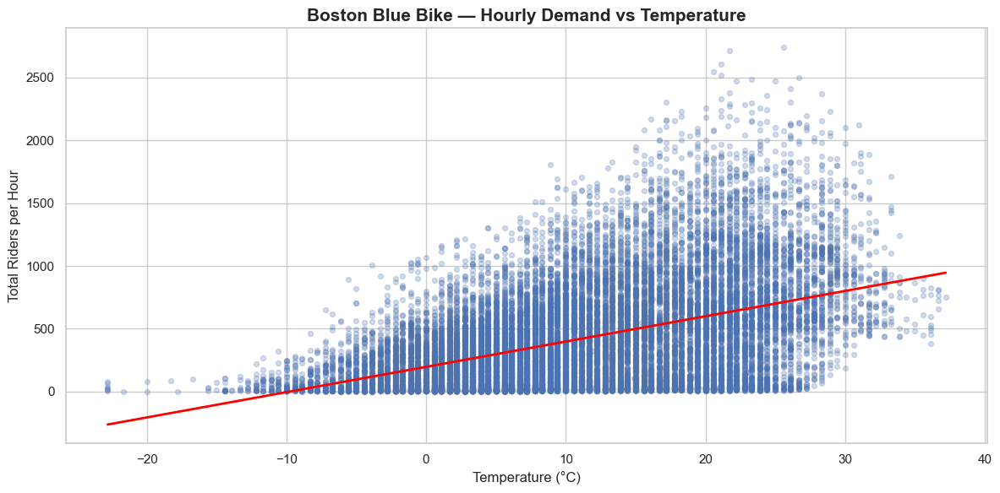

In [24]:
# Set visualisation theme
sns.set_theme(style="whitegrid", context="notebook")

# Create scatter plot with regression trend
plt.figure(figsize=(12, 6))

sns.regplot(
    data=df,
    x="temp_c",
    y="total_riders",
    scatter_kws={"alpha": 0.25, "s": 18},
    line_kws={"color": "red", "linewidth": 2},
    ci=None
)

plt.title(
    "Boston Blue Bike — Hourly Demand vs Temperature",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Temperature (°C)")
plt.ylabel("Total Riders per Hour")

plt.tight_layout()
plt.show()

### Hourly Demand vs Temperature — Key Observations

1. **Positive Association:** The scatter plot shows a positive relationship between temperature and hourly bike demand, with the regression line indicating higher demand at warmer temperatures.

2. **Demand Variability:** Rider counts vary substantially at similar temperatures, indicating that temperature alone does not explain hourly demand.

3. **High-Demand Peaks:** The highest observed demand values occur mainly at temperatures between approximately 20°C and 27°C.

4. **Potential Nonlinearity:** The relationship may not be entirely linear. Further analysis is needed to determine whether demand levels off or declines at higher temperatures.

**Conclusion:** Temperature is positively associated with hourly bike demand, but substantial variability remains at similar temperatures. Combining temperature with temporal and other weather features may improve forecasting performance.


### Hourly Demand vs Wind Speed

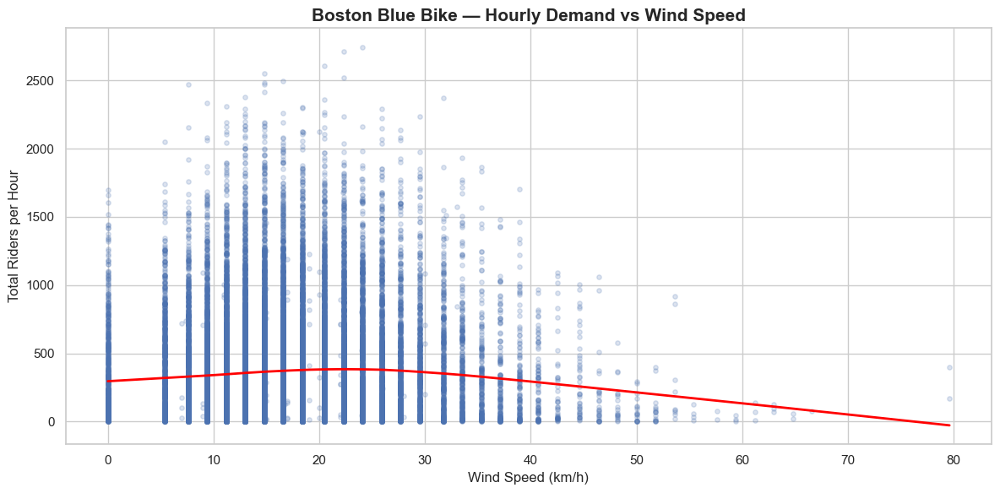

In [25]:
plt.figure(figsize=(12, 6))

sns.regplot(
    data=df,
    x="wind_kmh",
    y="total_riders",
    lowess=True,
    scatter_kws={"alpha": 0.20, "s": 15},
    line_kws={"color": "red", "linewidth": 2},
    ci=None
)

plt.title(
    "Boston Blue Bike — Hourly Demand vs Wind Speed",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Wind Speed (km/h)")
plt.ylabel("Total Riders per Hour")

plt.tight_layout()
plt.show()

#### Hourly Demand vs Wind Speed — Key Observations

1. **Potential Nonlinear Relationship:** The LOWESS trend initially rises slightly, peaks at approximately 20–25 km/h, and then declines as wind speed increases.

2. **Lower Demand at High Wind Speeds:** Observations at wind speeds above approximately 40 km/h generally show lower demand, with relatively few high-demand periods.

3. **High-Demand Peaks:** The largest demand observations are concentrated mainly at moderate wind speeds, particularly between approximately 10 and 25 km/h.

4. **Substantial Variability:** Demand varies considerably at similar wind speeds, indicating that wind speed alone does not explain hourly bike usage.

5. **Sparse Extreme Values:** Very high wind speeds are associated with relatively few observations. Conclusions about these conditions should therefore be treated cautiously.

6. **Forecasting Implications:** The `wind_kmh` feature may help tree-based models capture variations in demand associated with wind conditions.

**Conclusion:** The observed relationship between wind speed and hourly bike demand appears nonlinear, with demand generally lower at higher wind speeds. 

### Hourly Demand vs Atmospheric Pressure

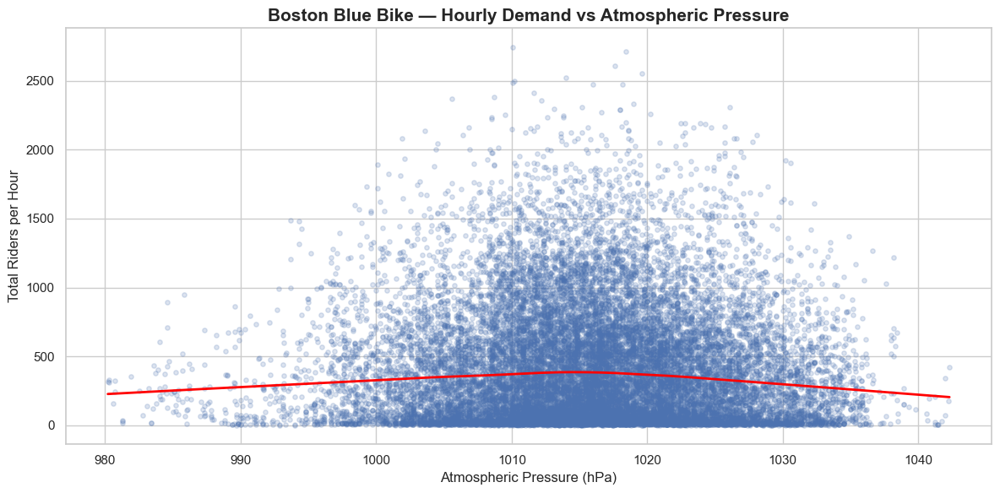

In [26]:
plt.figure(figsize=(12, 6))

sns.regplot(
    data=df,
    x="pressure_hpa",
    y="total_riders",
    lowess=True,
    scatter_kws={"alpha": 0.20, "s": 15},
    line_kws={"color": "red", "linewidth": 2},
    ci=None
)

plt.title(
    "Boston Blue Bike — Hourly Demand vs Atmospheric Pressure",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Atmospheric Pressure (hPa)")
plt.ylabel("Total Riders per Hour")

plt.tight_layout()
plt.show()

#### Hourly Demand vs Atmospheric Pressure — Key Observations

1. **Weak Nonlinear Pattern:** The LOWESS trend shows a slight increase in demand as atmospheric pressure rises towards approximately 1015–1020 hPa, followed by a gradual decline.

2. **Highest Demand Observations:** High-demand peaks occur mainly around 1010–1025 hPa, although high rider counts are not exclusive to this pressure range.

3. **Substantial Variability:** Rider counts vary widely at similar pressure levels, suggesting that atmospheric pressure alone does not explain hourly bike demand.

4. **Extreme Pressure Values:** The observed pressure values range approximately from 980 to 1043 hPa. These values should be checked for data quality, but the plot alone does not establish that any are erroneous.

5. **Forecasting Implications:** `pressure_hpa` may provide additional predictive information, but its independent contribution should be evaluated alongside temperature, wind speed, weather and temporal features.

**Conclusion:** Atmospheric pressure shows a relatively weak, nonlinear association with hourly bike demand.


In [29]:
import pandas as pd

# Calculate average hourly demand by year and month
monthly_yearly_demand = (
    df.groupby(["year", "month"], as_index=False)
    .agg(
        average_demand=("total_riders", "mean"),
        median_demand=("total_riders", "median"),
        observations=("total_riders", "count")
    )
)

display(monthly_yearly_demand.round(2))

,year,month,average_demand,median_demand,observations
0,2022,1,118.45,97.00,689
1,2022,2,164.87,126.00,670
2,2022,3,245.85,210.00,742
3,2022,4,380.92,360.50,720
4,2022,5,471.32,451.00,744
5,2022,6,539.63,508.50,720
6,2022,7,578.74,566.00,744
7,2022,8,654.84,600.50,744
8,2022,9,834.79,807.50,720
9,2022,10,560.44,532.50,744


### Demand by Month and Year

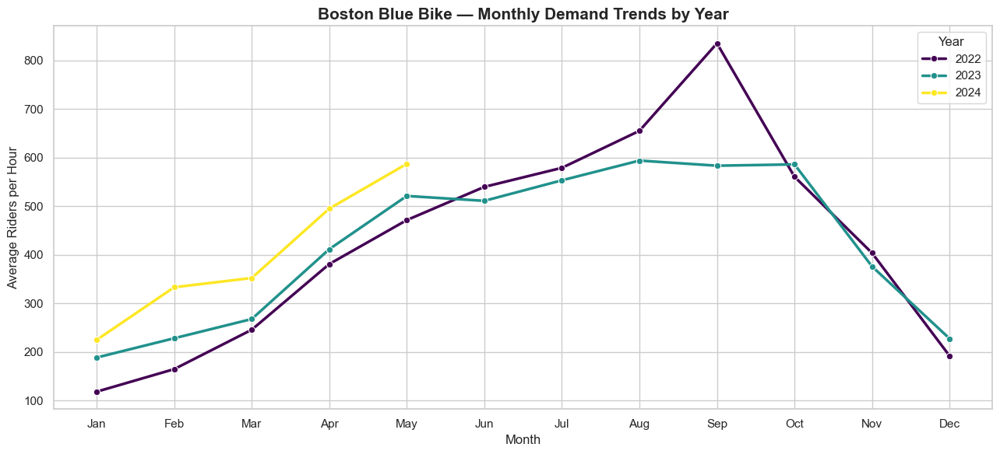

In [ ]:
plt.figure(figsize=(13, 6))

sns.lineplot(
    data=monthly_yearly_demand,
    x="month",
    y="average_demand",
    hue="year",
    marker="o",
    linewidth=2.5,
    palette="viridis"
)

plt.title(
    "Boston Blue Bike — Monthly Demand Trends by Year",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Month")
plt.ylabel("Average Riders per Hour")
plt.xticks(
    ticks=range(1, 13),
    labels=[
        "Jan", "Feb", "Mar", "Apr", "May", "Jun",
        "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
    ]
)
plt.legend(title="Year")
plt.tight_layout()
plt.show()

### Monthly Demand Trends by Year — Key Observations

1. **Seasonal Demand Pattern:** Demand generally increases from winter into spring and summer, before declining towards late autumn and winter.

2. **Exceptional September 2022 Peak:** September 2022 records the highest monthly average in the chart, at approximately 833 riders per hour. This peak is substantially higher than the corresponding months in 2023.

3. **More Moderate Pattern in 2023:** Demand increases through spring and summer 2023, reaching approximately 593 riders per hour in August, before remaining relatively stable in September and October.

4. **Higher Early-Year Demand in 2024:** From January to May, 2024 records higher average hourly demand than the corresponding months in 2022 and 2023.

5. **Year-to-Year Variability:** The differences between corresponding months indicate that monthly demand patterns are not identical across years. Seasonal effects may coexist with longer-term changes and unusual demand periods.

6. **Incomplete 2024 Data:** The 2024 series ends in May because the dataset covers only January–May of that year. Its missing later months must not be interpreted as zero demand.

**Conclusion:** Monthly demand exhibits seasonal variation and meaningful differences between years. 

### Correlation Analysis

In [31]:
# Select numerical features for correlation analysis
numeric_features = [
    "hour",
    "day",
    "weekday",
    "weekend",
    "holiday",
    "month",
    "year",
    "temp_c",
    "humidity",
    "wind_kmh",
    "pressure_hpa",
    "total_riders"
]

# Calculate Pearson correlations
correlation_matrix = df[numeric_features].corr(method="pearson")

# Display correlations with the target
target_correlations = (
    correlation_matrix["total_riders"]
    .drop("total_riders")
    .sort_values(ascending=False)
)

display(target_correlations.to_frame("correlation_with_total_riders").round(3))

,correlation_with_total_riders
temp_c,0.45
hour,0.42
month,0.19
wind_kmh,0.02
day,0.01
weekday,-0.02
pressure_hpa,-0.02
year,-0.03
weekend,-0.04
holiday,-0.05


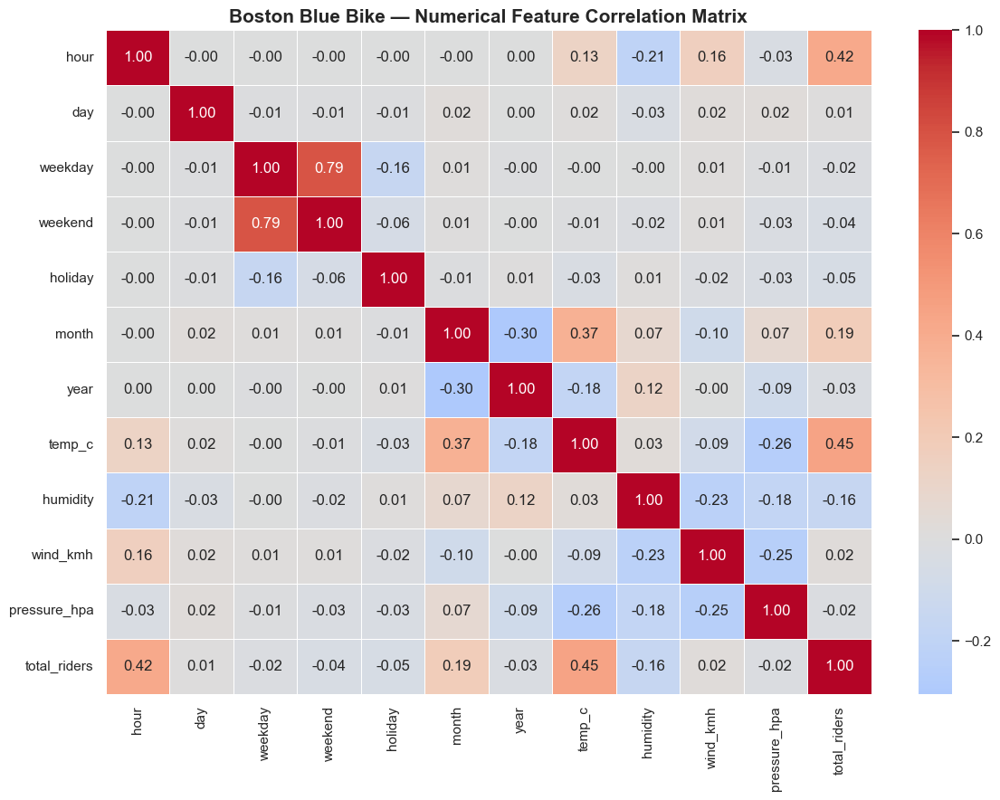

In [32]:
plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title(
    "Boston Blue Bike — Numerical Feature Correlation Matrix",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### Numerical Feature Correlation — Key Observations

1. **Temperature — Strongest Positive Correlation:** `temp_c` has the highest correlation with `total_riders` (r = 0.45), suggesting that warmer temperatures are associated with higher hourly demand.

2. **Hour of Day — Strong Positive Correlation:** `hour` has a positive correlation of 0.42 with demand, reinforcing the importance of daily usage patterns.

3. **Month — Weak Positive Correlation:** `month` has a correlation of 0.19 with demand, suggesting that monthly or seasonal patterns may contribute to demand variation.

4. **Humidity — Weak Negative Correlation:** `humidity` has a correlation of -0.16 with demand, indicating a modest negative linear association.

5. **Other Weather Variables:** `wind_kmh` (r = 0.02) and `pressure_hpa` (r = -0.02) have correlations close to zero, suggesting little linear association with demand when considered individually.

6. **Limited Linear Relationships:** `day`, `weekday`, `weekend`, `holiday` and `year` have correlations close to zero with the target. However, this does not mean these features are unhelpful; their effects may be nonlinear or depend on interactions with other variables.

7. **Feature Redundancy:** `weekday` and `weekend` have a correlation of approximately 0.79. This relationship should be reviewed because the features may encode overlapping calendar information.

**Conclusion:** Temperature and hour of day have the strongest individual linear associations with hourly demand. However, correlation alone cannot determine feature importance or predictive value, particularly for nonlinear tree-based models.


In [33]:
print("Weekday values:")
print(sorted(df["weekday"].unique()))

print("\nWeekend values:")
print(sorted(df["weekend"].unique()))

print("\nWeekday vs weekend:")
display(
    pd.crosstab(
        df["weekday"],
        df["weekend"],
        normalize="index"
    ).round(3)
)

Weekday values:
[np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6)]

Weekend values:
[np.int64(0), np.int64(1)]

Weekday vs weekend:


weekend,0,1
weekday,,
0,1.00,0.00
1,1.00,0.00
2,1.00,0.00
3,1.00,0.00
4,1.00,0.00
5,0.00,1.00
6,0.00,1.00


In [34]:
# Calculate average hourly demand by hour and day type
hourly_daytype_demand = (
    df.groupby(["hour", "weekend"])["total_riders"]
    .mean()
    .unstack()
    .rename(columns={0: "Weekday", 1: "Weekend"})
)

# Calculate the difference between weekday and weekend demand
hourly_daytype_demand["Difference"] = (
    hourly_daytype_demand["Weekday"]
    - hourly_daytype_demand["Weekend"]
)

# Calculate the percentage difference relative to weekend demand
hourly_daytype_demand["Difference_pct"] = (
    hourly_daytype_demand["Difference"]
    / hourly_daytype_demand["Weekend"]
    * 100
)

display(hourly_daytype_demand.round(2))

weekend,Weekday,Weekend,Difference,Difference_pct
hour,,,,
0,183.16,284.77,-101.61,-35.68
1,122.19,239.23,-117.04,-48.92
2,85.17,167.48,-82.31,-49.14
3,53.91,103.64,-49.73,-47.98
4,36.68,77.69,-41.01,-52.78
5,66.47,84.53,-18.06,-21.36
6,169.78,82.74,87.04,105.20
7,397.29,103.44,293.85,284.08
8,671.17,180.08,491.09,272.70


In [35]:
# Reset index for Plotly
plot_data = hourly_daytype_demand.reset_index()

# Plot percentage difference
fig = px.bar(
    plot_data,
    x="hour",
    y="Difference_pct",
    title="Boston Blue Bike — Weekday vs Weekend Demand Difference by Hour",
    labels={
        "hour": "Hour of Day",
        "Difference_pct": "Weekday Demand Difference (%)"
    },
    hover_data={
        "Weekday": ":.2f",
        "Weekend": ":.2f",
        "Difference": ":.2f",
        "Difference_pct": ":.2f"
    }
)

# Add a zero reference line
fig.add_hline(
    y=0,
    line_dash="dash",
    line_color="black"
)

fig.update_layout(
    template="plotly_white",
    title_x=0.5,
    xaxis=dict(
        tickmode="linear",
        dtick=1
    ),
    height=550
)

fig.show()

### Weekday vs Weekend Demand Difference — Key Observations

1. **Strong Morning Commuting Peak:** Weekday demand is approximately 284% higher than weekend demand at 07:00 and 273% higher at 08:00, indicating a pronounced weekday morning peak.

2. **Early Morning Demand Difference:** Between midnight and 05:00, weekday demand is approximately 21–53% lower than weekend demand.

3. **Weekend Midday Advantage:** Between 10:00 and 15:00, average weekend demand exceeds weekday demand, with the largest relative difference occurring at 14:00.

4. **Evening Demand Reversal:** Weekday demand becomes higher again from 16:00, reaching a difference of approximately 41% at 17:00.

5. **Smaller Late-Evening Differences:** From 19:00 to 23:00, weekday demand remains moderately higher, with the difference narrowing to approximately 7% by 23:00.

6. **Strong Hour–Day-Type Interaction:** The weekday–weekend demand difference changes substantially throughout the day, demonstrating that the relationship between hour and demand depends on the type of day.

**Conclusion:** Hourly demand follows distinct weekday and weekend patterns. These differences may reflect commuting and leisure travel behaviour. Including hour and weekend-related features in the forecasting models may help capture these recurring patterns.


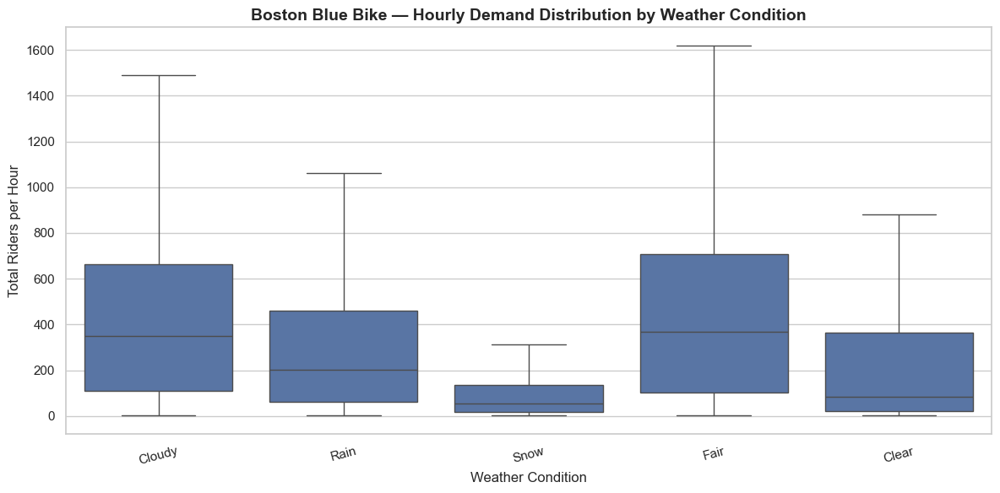

In [36]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="weather",
    y="total_riders",
    showfliers=False
)

plt.title(
    "Boston Blue Bike — Hourly Demand Distribution by Weather Condition",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Weather Condition")
plt.ylabel("Total Riders per Hour")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Demand Distribution by Weather Condition — Key Observations

1. **Highest Median Demand:** Fair conditions have the highest median hourly demand, followed closely by Cloudy conditions.

2. **Lowest Demand During Snow:** Snow has the lowest median demand and the narrowest interquartile range, indicating generally lower demand and less variation than the other weather categories.

3. **High Demand Variability:** Fair and Cloudy conditions exhibit wide distributions, suggesting that hourly demand varies considerably under these conditions.

4. **Rain Reduces Typical Demand:** Rain has a lower median demand than Fair and Cloudy conditions, although substantial demand still occurs during some rainy hours.

5. **Overlapping Distributions:** The distributions overlap considerably, indicating that weather condition alone does not fully explain hourly demand.

6. **High-Demand Peaks Occur Across Conditions:** The upper whiskers extend to relatively high demand levels under Fair and Cloudy conditions, suggesting that substantial demand can occur under both.

**Conclusion:** Weather conditions are associated with differences in hourly demand, particularly between Snow and Fair or Cloudy conditions. However, demand also depends on temporal patterns and other factors. The observed differences do not establish that weather alone causes changes in ridership.


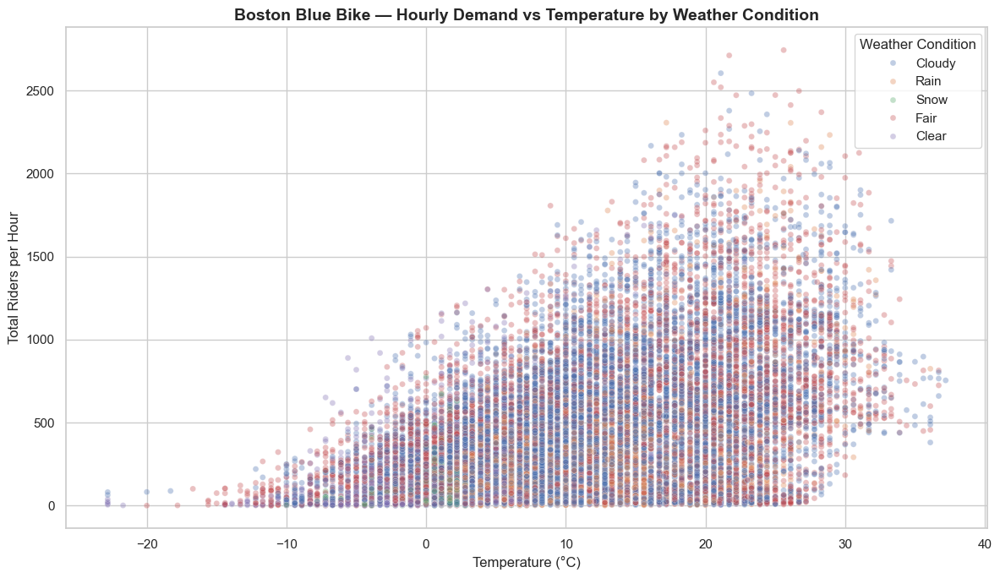

In [37]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df,
    x="temp_c",
    y="total_riders",
    hue="weather",
    alpha=0.35,
    s=25
)

plt.title(
    "Boston Blue Bike — Hourly Demand vs Temperature by Weather Condition",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Temperature (°C)")
plt.ylabel("Total Riders per Hour")
plt.legend(title="Weather Condition")
plt.tight_layout()
plt.show()

In [38]:

# Create 2°C temperature intervals
temperature_bins = np.arange(
    np.floor(df["temp_c"].min() / 2) * 2,
    np.ceil(df["temp_c"].max() / 2) * 2 + 2,
    2
)

df["temperature_bin"] = pd.cut(
    df["temp_c"],
    bins=temperature_bins,
    right=False
)

# Calculate demand statistics for each temperature interval
temperature_demand = (
    df.groupby("temperature_bin", observed=True)["total_riders"]
    .agg(["count", "mean", "median", "std"])
    .reset_index()
)

# Calculate interval midpoints for plotting
temperature_demand["temperature_midpoint"] = (
    temperature_demand["temperature_bin"]
    .apply(lambda interval: interval.mid)
)

display(temperature_demand.round(2))

,temperature_bin,count,mean,median,std,temperature_midpoint
0,"[-24.0, -22.0)",7,34.71,24.00,28.97,-23.00
1,"[-22.0, -20.0)",1,2.00,2.00,NaN,-21.00
2,"[-20.0, -18.0)",3,57.67,83.00,49.17,-19.00
3,"[-18.0, -16.0)",2,52.00,52.00,70.71,-17.00
4,"[-16.0, -14.0)",16,31.38,12.00,36.36,-15.00
5,"[-14.0, -12.0)",32,45.34,27.00,49.34,-13.00
6,"[-12.0, -10.0)",56,69.18,59.00,66.76,-11.00
7,"[-10.0, -8.0)",143,82.68,51.00,84.97,-9.00
8,"[-8.0, -6.0)",228,114.99,63.50,126.98,-7.00
9,"[-6.0, -4.0)",278,154.17,109.50,155.11,-5.00


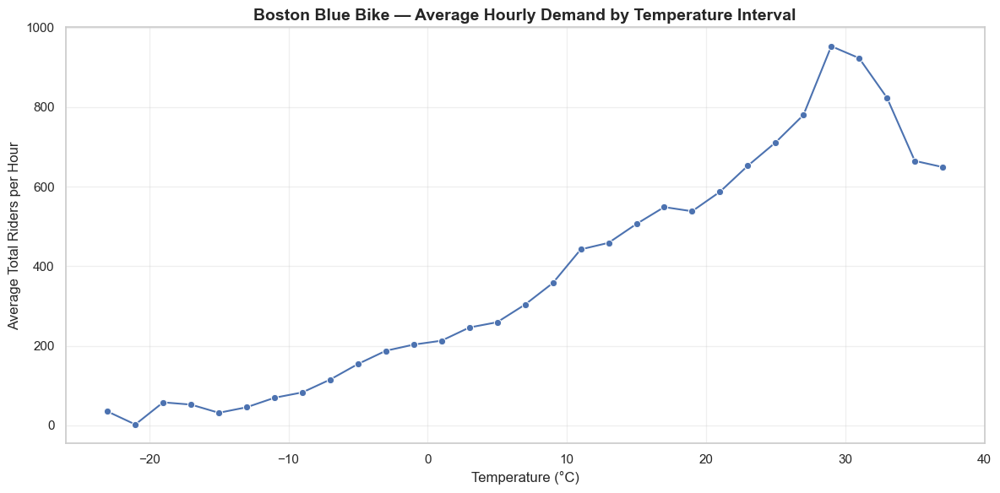

In [39]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=temperature_demand,
    x="temperature_midpoint",
    y="mean",
    marker="o"
)

plt.title(
    "Boston Blue Bike — Average Hourly Demand by Temperature Interval",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Temperature (°C)")
plt.ylabel("Average Total Riders per Hour")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Key Observations

1. **Positive relationship between temperature and bike demand:** Average hourly bike demand generally increases as temperature rises, suggesting that warmer weather encourages bike-sharing activity.

2. **Peak demand occurs at moderate-to-warm temperatures:** The highest average hourly demand is observed around 29°C, at approximately 950 riders per hour. This suggests that demand increases substantially during warmer conditions.

3. **Demand declines at very low temperatures:** Average demand is relatively low at temperatures below 0°C, indicating that cold conditions may discourage bike-sharing activity.

4. **Demand decreases at higher temperatures:** After reaching its peak around 29°C, average demand declines as temperatures rise further. This suggests that extremely warm conditions may discourage some users from cycling.

5. **The relationship is nonlinear:** Demand does not increase at a constant rate with temperature. It rises gradually at lower temperatures, increases more rapidly at moderate temperatures, and declines beyond the observed peak.

6. **Temperature alone does not explain demand:** Although the plot reveals a clear relationship, other factors—including hour of day, day of week, season, holidays, and weather conditions—may also influence bike demand.

### Conclusion

Temperature appears to be an important predictor of hourly bike demand, with the highest average demand occurring around 29°C. The nonlinear relationship suggests that the effect of temperature should be explored further during feature analysis and modelling. However, this plot demonstrates an association rather than a causal relationship.

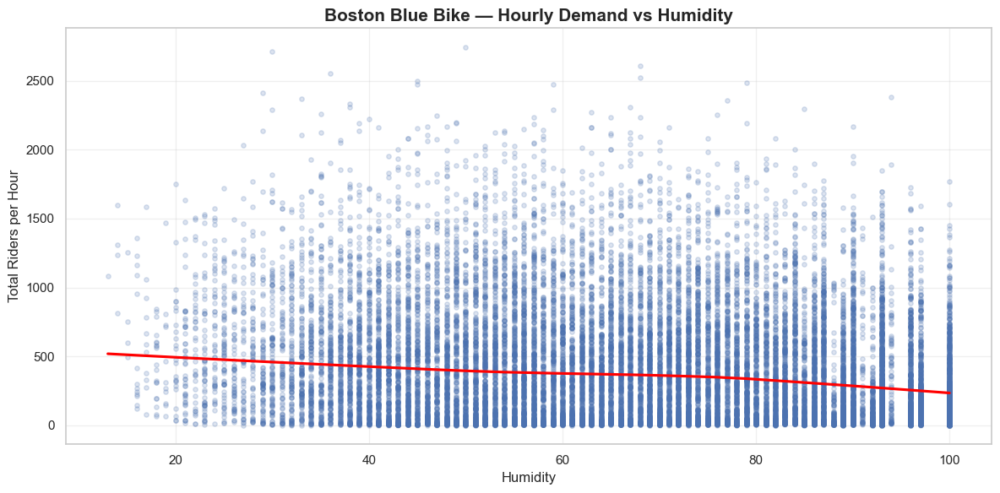

In [40]:
# Hourly demand vs humidity

plt.figure(figsize=(12, 6))

sns.regplot(
    data=df,
    x="humidity",
    y="total_riders",
    scatter_kws={"alpha": 0.2, "s": 15},
    line_kws={"color": "red"},
    lowess=True,
    ci=None
)

plt.title("Boston Blue Bike — Hourly Demand vs Humidity", fontsize=15, fontweight="bold")
plt.xlabel("Humidity")
plt.ylabel("Total Riders per Hour")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()